NLP Final Project - Home Depot Search Relevance

In [3]:
import pandas as pd
from pathlib import Path

data_dir = Path(r"C:\Users\sadhw\Downloads\IAA\NLP\Final Project\Data")

# Read CSVs
train = pd.read_csv(data_dir / "train.csv", encoding="latin-1")
test = pd.read_csv(data_dir / "test.csv", encoding="latin-1")
sample_submission = pd.read_csv(data_dir / "sample_submission.csv", encoding="utf-8")
product_descriptions = pd.read_csv(data_dir / "product_descriptions.csv", encoding="utf-8")
attributes = pd.read_csv(data_dir / "attributes.csv", encoding="utf-8")

# Quick sanity check
print("train shape:", train.shape)
print("test shape:", test.shape)
print("sample_submission shape:", sample_submission.shape)
print("product_descriptions shape:", product_descriptions.shape)
print("attributes shape:", attributes.shape)

print("\nTrain head:")
display(train.head())

print("\nTest head:")
display(test.head())

print("\nProduct descriptions head:")
display(product_descriptions.head())

print("\nAttributes head:")
display(attributes.head())

train shape: (74067, 5)
test shape: (166693, 4)
sample_submission shape: (166693, 2)
product_descriptions shape: (124428, 2)
attributes shape: (2044803, 3)

Train head:


,id,product_uid,product_title,search_term,relevance
0,2,100001,Simpson Strong-Tie 12-Gauge Angle,angle bracket,3.00
1,3,100001,Simpson Strong-Tie 12-Gauge Angle,l bracket,2.50
2,9,100002,BEHR Premium Textured DeckOver 1-gal. #SC-141 ...,deck over,3.00
3,16,100005,Delta Vero 1-Handle Shower Only Faucet Trim Ki...,rain shower head,2.33
4,17,100005,Delta Vero 1-Handle Shower Only Faucet Trim Ki...,shower only faucet,2.67



Test head:


,id,product_uid,product_title,search_term
0,1,100001,Simpson Strong-Tie 12-Gauge Angle,90 degree bracket
1,4,100001,Simpson Strong-Tie 12-Gauge Angle,metal l brackets
2,5,100001,Simpson Strong-Tie 12-Gauge Angle,simpson sku able
3,6,100001,Simpson Strong-Tie 12-Gauge Angle,simpson strong ties
4,7,100001,Simpson Strong-Tie 12-Gauge Angle,simpson strong tie hcc668



Product descriptions head:


,product_uid,product_description
0,100001,"Not only do angles make joints stronger, they ..."
1,100002,BEHR Premium Textured DECKOVER is an innovativ...
2,100003,Classic architecture meets contemporary design...
3,100004,The Grape Solar 265-Watt Polycrystalline PV So...
4,100005,Update your bathroom with the Delta Vero Singl...



Attributes head:


,product_uid,name,value
0,100001.0,Bullet01,Versatile connector for various 90° connection...
1,100001.0,Bullet02,Stronger than angled nailing or screw fastenin...
2,100001.0,Bullet03,Help ensure joints are consistently straight a...
3,100001.0,Bullet04,Dimensions: 3 in. x 3 in. x 1-1/2 in.
4,100001.0,Bullet05,Made from 12-Gauge steel


In [4]:
df = train.merge(product_descriptions, on="product_uid", how="left")
df = df.merge(attributes, on="product_uid", how="left")
display(df.head())

,id,product_uid,product_title,search_term,relevance,product_description,name,value
0,2,100001,Simpson Strong-Tie 12-Gauge Angle,angle bracket,3.0,"Not only do angles make joints stronger, they ...",Bullet01,Versatile connector for various 90° connection...
1,2,100001,Simpson Strong-Tie 12-Gauge Angle,angle bracket,3.0,"Not only do angles make joints stronger, they ...",Bullet02,Stronger than angled nailing or screw fastenin...
2,2,100001,Simpson Strong-Tie 12-Gauge Angle,angle bracket,3.0,"Not only do angles make joints stronger, they ...",Bullet03,Help ensure joints are consistently straight a...
3,2,100001,Simpson Strong-Tie 12-Gauge Angle,angle bracket,3.0,"Not only do angles make joints stronger, they ...",Bullet04,Dimensions: 3 in. x 3 in. x 1-1/2 in.
4,2,100001,Simpson Strong-Tie 12-Gauge Angle,angle bracket,3.0,"Not only do angles make joints stronger, they ...",Bullet05,Made from 12-Gauge steel


In [5]:
bullet_attributes = attributes.loc[
    attributes["name"].str.startswith("Bullet", na=False), ["product_uid", "value"]
].dropna(subset=["value"]).copy()
bullet_attributes["value"] = bullet_attributes["value"].str.strip()
bullet_attributes = bullet_attributes[bullet_attributes["value"].ne("")]

attribute_sentences = (
    bullet_attributes.groupby("product_uid", as_index=False)["value"]
    .agg(" ".join)
    .rename(columns={"value": "attribute_sentence"})
)

df = train.merge(product_descriptions, on="product_uid", how="left")
df = df.merge(attribute_sentences, on="product_uid", how="left")
df = df.groupby("id", as_index=False).agg(
    {
        "product_uid": "first",
        "product_title": "first",
        "search_term": "first",
        "relevance": "first",
        "product_description": "first",
        "attribute_sentence": "first",
    }
)

display(df.head())

,id,product_uid,product_title,search_term,relevance,product_description,attribute_sentence
0,2,100001,Simpson Strong-Tie 12-Gauge Angle,angle bracket,3.00,"Not only do angles make joints stronger, they ...",Versatile connector for various 90° connection...
1,3,100001,Simpson Strong-Tie 12-Gauge Angle,l bracket,2.50,"Not only do angles make joints stronger, they ...",Versatile connector for various 90° connection...
2,9,100002,BEHR Premium Textured DeckOver 1-gal. #SC-141 ...,deck over,3.00,BEHR Premium Textured DECKOVER is an innovativ...,"Revives wood and composite decks, railings, po..."
3,16,100005,Delta Vero 1-Handle Shower Only Faucet Trim Ki...,rain shower head,2.33,Update your bathroom with the Delta Vero Singl...,"Includes the trim kit only, the rough-in kit (..."
4,17,100005,Delta Vero 1-Handle Shower Only Faucet Trim Ki...,shower only faucet,2.67,Update your bathroom with the Delta Vero Singl...,"Includes the trim kit only, the rough-in kit (..."


,missing_or_blank,mean_words,median_words,mean_characters,unique_texts
search_term,0,3.24,3.0,18.93,11791
product_title,0,12.80,12.0,67.51,53445
product_description,0,142.01,121.0,871.11,49905
attribute_sentence,17520,56.08,41.0,332.58,33684


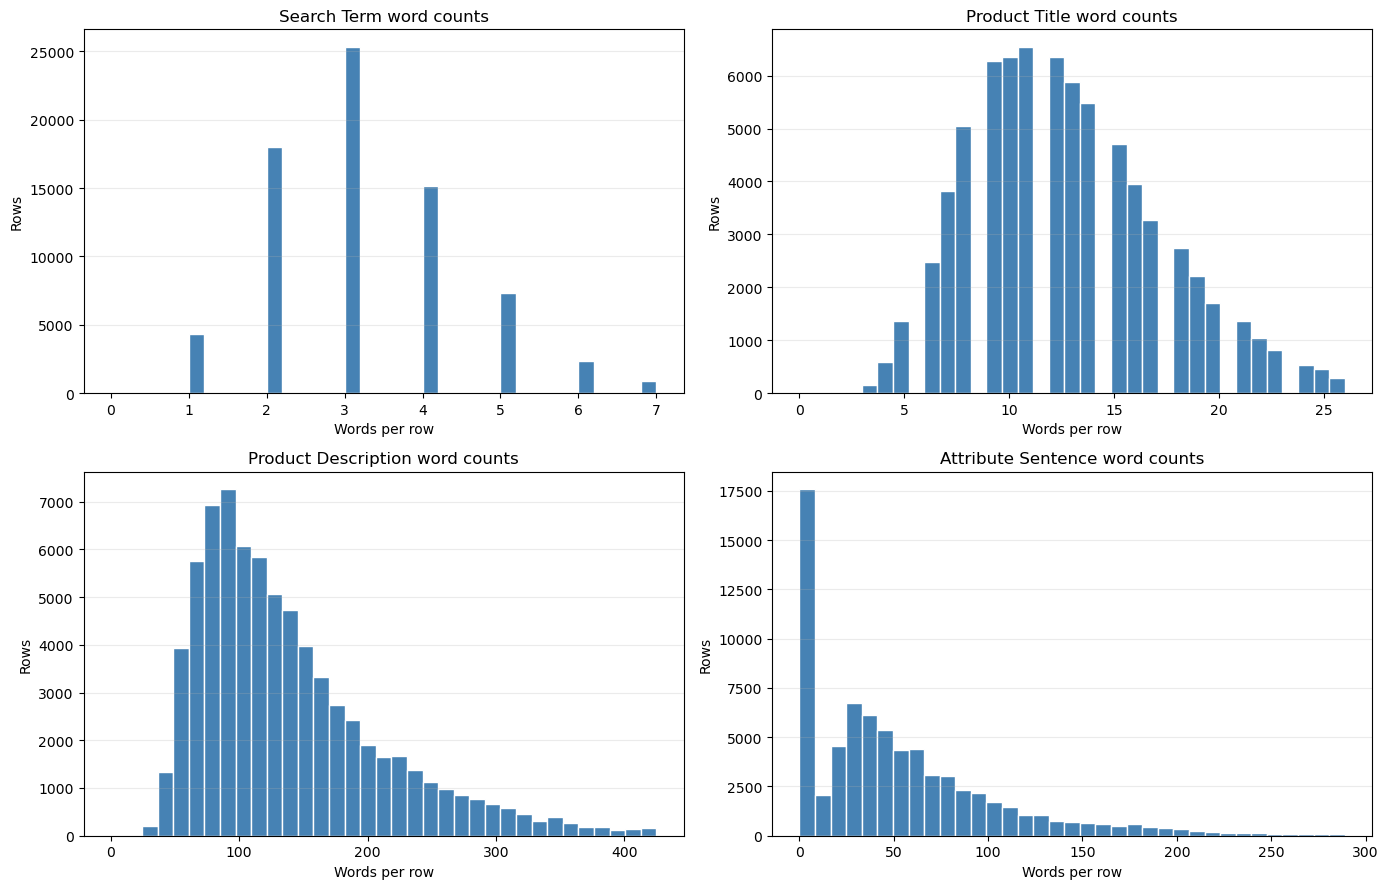

,text_column,term,count
0,search_term,door,2696
1,search_term,light,2072
2,search_term,inch,1503
3,search_term,shower,1468
4,search_term,wall,1451
5,search_term,white,1371
6,search_term,wood,1368
7,search_term,tile,1350
8,search_term,paint,1157
9,search_term,cabinet,1061


In [6]:
import re
from collections import Counter

import matplotlib.pyplot as plt

text_columns = [
    "search_term",
    "product_title",
    "product_description",
    "attribute_sentence",
]
missing_text_columns = [column for column in text_columns if column not in df.columns]
if missing_text_columns:
    raise KeyError(f"Expected text columns are missing from df: {missing_text_columns}")

# Keep original text unchanged and create normalized lowercase text for analysis.
for column in text_columns:
    clean_column = f"{column}_clean"
    df[clean_column] = (
        df[column]
        .fillna("")
        .astype(str)
        .str.lower()
        .str.replace(r"[^a-z0-9]+", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

clean_columns = [f"{column}_clean" for column in text_columns]
text_eda = pd.DataFrame(index=text_columns)
text_eda["missing_or_blank"] = [
    (df[column].isna() | df[column].astype("string").str.strip().eq("")).sum()
    for column in text_columns
]
text_eda["mean_words"] = [df[clean].str.split().str.len().mean() for clean in clean_columns]
text_eda["median_words"] = [df[clean].str.split().str.len().median() for clean in clean_columns]
text_eda["mean_characters"] = [df[clean].str.len().mean() for clean in clean_columns]
text_eda["unique_texts"] = [df[clean].nunique() for clean in clean_columns]
display(text_eda.round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for column, clean, ax in zip(text_columns, clean_columns, axes.flat):
    word_counts = df[clean].str.split().str.len()
    upper_limit = max(1, word_counts.quantile(0.99))
    ax.hist(word_counts, bins=35, range=(0, upper_limit), color="steelblue", edgecolor="white")
    ax.set(title=f"{column.replace('_', ' ').title()} word counts", xlabel="Words per row", ylabel="Rows")
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

stop_words = {
    "the", "and", "for", "with", "this", "that", "from", "are", "was", "were",
    "has", "have", "had", "you", "your", "our", "its", "into", "out", "not",
    "but", "can", "will", "all", "each", "per", "use", "used", "in", "on", "of",
    "to", "a", "an", "is", "it", "by", "as", "or", "be", "at", "up", "more",
}
top_terms = []
for column, clean in zip(text_columns, clean_columns):
    counts = Counter(
        token
        for text in df[clean].dropna()
        for token in re.findall(r"[a-z0-9]+", text)
        if len(token) > 2 and token not in stop_words
    )
    top_terms.extend(
        {"text_column": column, "term": term, "count": count}
        for term, count in counts.most_common(15)
    )
pd.DataFrame(top_terms).head(15)

### Evaluating Current Model

Labeled search-product pairs: 74,067
Mean relevance:               2.38 / 3
Highly relevant (>= 2.67):    46.4%
Somewhat relevant (2.0-2.66):  37.6%
Poor (< 2.0):                  16.1%


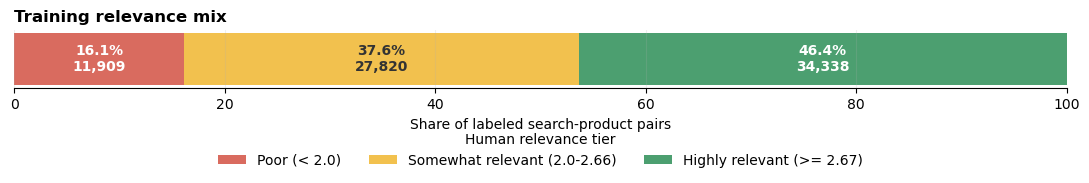

In [7]:
# Baseline view of the human relevance labels in the labeled training data.
# This summarizes the existing search results; it is not a model-performance metric.
lab = df.loc[df["relevance"].notna()].copy()
r = lab["relevance"].astype(float)

if r.empty:
    raise ValueError("No labeled training relevance scores are available in df.")
if not r.between(1, 3).all():
    raise ValueError("Expected relevance scores to be between 1 and 3.")

print(f"Labeled search-product pairs: {len(r):,}")
print(f"Mean relevance:               {r.mean():.2f} / 3")
print(f"Highly relevant (>= 2.67):    {(r >= 2.67).mean():.1%}")
print(f"Somewhat relevant (2.0-2.66):  {((r >= 2) & (r < 2.67)).mean():.1%}")
print(f"Poor (< 2.0):                  {(r < 2).mean():.1%}")

category_counts = pd.Series(
    {
        "Poor (< 2.0)": (r < 2).sum(),
        "Somewhat relevant (2.0-2.66)": ((r >= 2) & (r < 2.67)).sum(),
        "Highly relevant (>= 2.67)": (r >= 2.67).sum(),
    }
)
colors = ["#D96B5F", "#F2C14E", "#4C9F70"]
fig, ax = plt.subplots(figsize=(11, 2.8))
left = 0
for (category, count), color in zip(category_counts.items(), colors):
    share = count / len(r) * 100
    ax.barh("Training results", share, left=left, color=color, height=0.55, label=category)
    if share >= 8:
        ax.text(
            left + share / 2,
            0,
            f"{share:.1f}%\n{count:,}",
            ha="center",
            va="center",
            color="white" if color != "#F2C14E" else "#333333",
            fontweight="bold",
        )
    left += share

ax.set_xlim(0, 100)
ax.set_xlabel("Share of labeled search-product pairs")
ax.set_title("Training relevance mix", loc="left", fontweight="bold")
ax.set_yticks([])
ax.legend(title="Human relevance tier", bbox_to_anchor=(0.5, -0.55), loc="upper center", ncol=3, frameon=False)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

### Semantic+Tf-Idf Correlation Analysis

In [8]:
import re

import numpy as np
from gensim.models import Word2Vec
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer

# Compare the search phrase with the combined title, description, and attribute bullets.
similarity_fields = ["product_title", "product_description", "attribute_sentence"]
required_fields = ["id", "search_term", "relevance", *similarity_fields]
missing_fields = [field for field in required_fields if field not in df.columns]
if missing_fields:
    raise KeyError(f"Required similarity-analysis fields are missing: {missing_fields}")

labeled_df = df.loc[df["relevance"].notna()].copy()
if labeled_df.empty:
    raise ValueError("No labeled training rows are available for similarity analysis.")
if labeled_df["id"].duplicated().any():
    raise ValueError("Expected one training observation per id for similarity analysis.")

def normalize_for_similarity(text):
    if pd.isna(text):
        return ""
    return " ".join(re.findall(r"[a-z0-9]+", str(text).lower()))

queries = labeled_df["search_term"].map(normalize_for_similarity)
product_text = labeled_df[similarity_fields].fillna("").astype(str).agg(" ".join, axis=1)
product_text = product_text.map(normalize_for_similarity)

# Row-wise TF-IDF cosine similarity: shared weighted terms between query and product text.
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
all_text = pd.concat([queries, product_text], ignore_index=True)
tfidf_matrix = tfidf.fit_transform(all_text)
query_tfidf = tfidf_matrix[:len(labeled_df)]
product_tfidf = tfidf_matrix[len(labeled_df):]
tfidf_similarity = np.asarray(query_tfidf.multiply(product_tfidf).sum(axis=1)).ravel()

# In-domain Word2Vec gives a distributional semantic score without downloading a model.
query_tokens = [text.split() for text in queries]
product_tokens = [text.split() for text in product_text]
embedding_corpus = query_tokens + product_tokens
word2vec = Word2Vec(
    sentences=embedding_corpus,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    seed=42,
    epochs=8,
)

def mean_word_vector(tokens):
    known_vectors = [word2vec.wv[token] for token in tokens if token in word2vec.wv]
    if not known_vectors:
        return np.zeros(word2vec.vector_size, dtype=np.float32)
    return np.mean(known_vectors, axis=0)

query_vectors = np.vstack([mean_word_vector(tokens) for tokens in query_tokens])
product_vectors = np.vstack([mean_word_vector(tokens) for tokens in product_tokens])
dot_products = np.einsum("ij,ij->i", query_vectors, product_vectors)
norm_products = np.linalg.norm(query_vectors, axis=1) * np.linalg.norm(product_vectors, axis=1)
semantic_similarity = np.divide(
    dot_products,
    norm_products,
    out=np.zeros_like(dot_products, dtype=float),
    where=norm_products > 0,
)

similarity_results = labeled_df[["id", "search_term", "product_title", "relevance"]].copy()
similarity_results["tfidf_similarity"] = tfidf_similarity
similarity_results["semantic_similarity"] = semantic_similarity
if not np.isfinite(similarity_results[["tfidf_similarity", "semantic_similarity"]]).all().all():
    raise ValueError("Similarity calculations produced non-finite values.")

df = df.drop(columns=["tfidf_similarity", "semantic_similarity"], errors="ignore").merge(
    similarity_results[["id", "tfidf_similarity", "semantic_similarity"]],
    on="id",
    how="left",
    validate="one_to_one",
)

correlation_rows = []
for score_column in ["tfidf_similarity", "semantic_similarity"]:
    result = spearmanr(similarity_results[score_column], similarity_results["relevance"])
    if not np.isfinite(result.statistic):
        raise ValueError(f"Spearman correlation is undefined for {score_column}.")
    correlation_rows.append(
        {
            "similarity_measure": score_column,
            "spearman_rho": result.statistic,
            "p_value": result.pvalue,
            "observations": len(similarity_results),
        }
    )

similarity_correlations = pd.DataFrame(correlation_rows).set_index("similarity_measure")
display(similarity_correlations.round(4))
display(similarity_results.head(10).round({"relevance": 2, "tfidf_similarity": 4, "semantic_similarity": 4}))
print("Per-observation similarities are stored in df['tfidf_similarity'] and df['semantic_similarity'].")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

,spearman_rho,p_value,observations
similarity_measure,,,
tfidf_similarity,0.2789,0.0,74067
semantic_similarity,0.0883,0.0,74067


,id,search_term,product_title,relevance,tfidf_similarity,semantic_similarity
0,2,angle bracket,Simpson Strong-Tie 12-Gauge Angle,3.00,0.0160,0.6061
1,3,l bracket,Simpson Strong-Tie 12-Gauge Angle,2.50,0.0000,0.6259
2,9,deck over,BEHR Premium Textured DeckOver 1-gal. #SC-141 ...,3.00,0.0125,0.6014
3,16,rain shower head,Delta Vero 1-Handle Shower Only Faucet Trim Ki...,2.33,0.0174,0.6390
4,17,shower only faucet,Delta Vero 1-Handle Shower Only Faucet Trim Ki...,2.67,0.1237,0.7691
5,18,convection otr,Whirlpool 1.9 cu. ft. Over the Range Convectio...,3.00,0.0238,0.6658
6,20,microwave over stove,Whirlpool 1.9 cu. ft. Over the Range Convectio...,2.67,0.0273,0.6795
7,21,microwaves,Whirlpool 1.9 cu. ft. Over the Range Convectio...,3.00,0.0000,0.4675
8,23,emergency light,Lithonia Lighting Quantum 2-Light Black LED Em...,2.67,0.0567,0.6774
9,27,mdf 3/4,House of Fara 3/4 in. x 3 in. x 8 ft. MDF Flut...,3.00,0.1302,0.7207


Per-observation similarities are stored in df['tfidf_similarity'] and df['semantic_similarity'].


## Product topic modeling with NMF

Each product appears once in the topic corpus, with its title, description, and attribute bullets combined. The notebook compares 5, 10, 15, and 20 topics using one unigram/bigram TF-IDF matrix. Review the displayed top terms and redundancy diagnostics before settling on a final topic count; the selected 10-topic view is an initial inspection candidate.

Unique products modeled: 124,428
TF-IDF matrix: 124,428 products x 50,000 terms

5 topics — top 10 words per topic


,topic,top_words
0,Topic 1,"easy, steel, use, design, door, construction, ..."
1,Topic 2,"tile, residential, thinset, indoor, frost, ite..."
2,Topic 3,"paint, fee following, following states, states..."
3,Topic 4,"rug, vary slightly, slightly, vary, dimensions..."
4,Topic 5,"light, watt, bulb, energy, led, light bulb, li..."



10 topics — top 10 words per topic


,topic,top_words
0,Topic 1,"ft, easy, power, use, protection, air, high, s..."
1,Topic 2,"tile, thinset, indoor, frost, residential, rec..."
2,Topic 3,"paint, fee following, following states, states..."
3,Topic 4,"rug, vary slightly, slightly, vary, dimensions..."
4,Topic 5,"light, watt, bulb, energy, light bulb, incande..."
5,Topic 6,"door, hardware, finish, glass, cabinet, includ..."
6,Topic 7,"spray paint, gloss, paint, hedrix, paint produ..."
7,Topic 8,"steel, proposition 65, proposition, nbsp propo..."
8,Topic 9,"faucet, handle, valve, shower, water, brass, w..."
9,Topic 10,"flooring, grade, laminate, grade installation,..."



15 topics — top 10 words per topic


,topic,top_words
0,Topic 1,"ft, easy, heavy, duty, durable, resistant, hea..."
1,Topic 2,"tile, thinset, indoor, frost, residential, rec..."
2,Topic 3,"paint, fee following, following states, states..."
3,Topic 4,"rug, vary slightly, slightly, vary, dimensions..."
4,Topic 5,"energy, bulb, light bulb, watt, light, hours, ..."
5,Topic 6,"cabinet, vanity, storage, drawer, shelf, solid..."
6,Topic 7,"spray paint, gloss, paint, hedrix, paint produ..."
7,Topic 8,"steel, proposition 65, proposition, residents ..."
8,Topic 9,"faucet, handle, shower, valve, watersense, chr..."
9,Topic 10,"light, watt, glass, lighting, fixture, bulbs, ..."



20 topics — top 10 words per topic


,topic,top_words
0,Topic 1,"ft, outdoor, easy, resistant, fabric, durable,..."
1,Topic 2,"tile, thinset, frost, indoor, residential, rec..."
2,Topic 3,"paint, fee following, following states, states..."
3,Topic 4,"rug, vary slightly, slightly, dimensions, vary..."
4,Topic 5,"energy, bulb, light bulb, watt, light, hours, ..."
5,Topic 6,"vanity, sink, cabinet, faucet, hardware, bathr..."
6,Topic 7,"gloss, spray paint, hedrix, paint, paint produ..."
7,Topic 8,"proposition, proposition 65, residents nbsp, n..."
8,Topic 9,"faucet, handle, watersense, shower, valve, chr..."
9,Topic 10,"light, watt, lighting, fixture, glass, bulbs, ..."


,reconstruction_error,mean_topic_similarity,max_topic_similarity,mean_top10_word_overlap
n_topics,,,,
5,346.1240,0.1103,0.2244,0.0000
10,343.6620,0.1101,0.3489,0.0067
15,341.9369,0.1080,0.3011,0.0086
20,340.5926,0.0892,0.3165,0.0079


Interpretation: inspect the top words for coherent, distinct themes; lower mean topic cosine and top-10 word overlap indicate less redundancy.


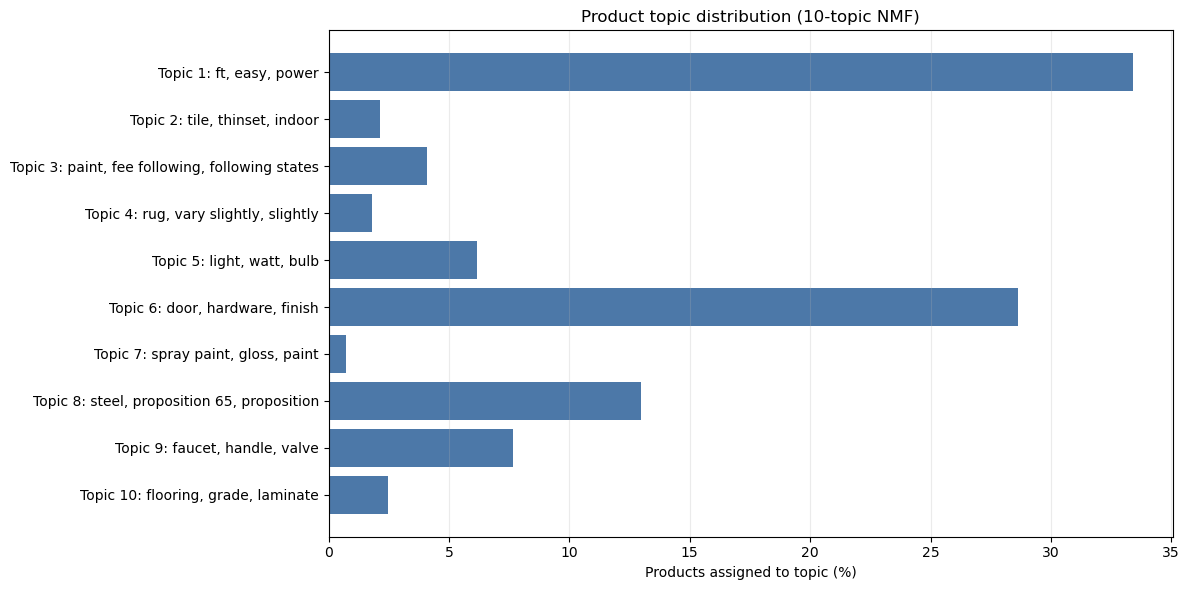

,topic,topic_terms,rank,product_uid,product_title,topic_weight
0,1,"ft, easy, power",1,194642,Bosch 18-Volt Compact Tough Hammer Drill Drive...,0.036907
1,1,"ft, easy, power",2,133074,Maytag AquaLift 5.8 cu. ft. Gas Range with Sel...,0.036128
2,1,"ft, easy, power",3,116227,DEWALT 20-Volt Lithium-Ion 1/2 in. Cordless Br...,0.035780
3,1,"ft, easy, power",4,199555,Makita 36-Volt X2 LXT Lithium-Ion Cordless Cha...,0.035603
4,1,"ft, easy, power",5,146545,Cub Cadet 40-Volt Max Lithium-Ion Electric Cor...,0.035523
5,2,"tile, thinset, indoor",1,135100,Daltile Marissa Carrara 3 in. x 12 in. Ceramic...,0.149925
6,2,"tile, thinset, indoor",2,195264,Daltile Identity Matte Oxford Brown 5/8 in. x ...,0.149689
7,2,"tile, thinset, indoor",3,177178,Daltile Identity Matte Metro Taupe 5/8 in. x 1...,0.149566
8,2,"tile, thinset, indoor",4,101758,Daltile Marissa Carrara 3 in. x 10 in. Ceramic...,0.149026
9,2,"tile, thinset, indoor",5,142839,ELIANE Melbourne Sand 3 in. x 8 in. Ceramic Li...,0.148550


In [9]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

product_fields = ["product_title", "product_description", "attribute_sentence"]
if any(field not in train.columns for field in ["product_uid", "product_title"]):
    raise KeyError("train must include product_uid and product_title for product-level topics.")
if "product_description" not in product_descriptions.columns:
    raise KeyError("product_descriptions must include product_description.")
if "attribute_sentence" not in attribute_sentences.columns:
    raise KeyError("attribute_sentences must include attribute_sentence.")

# Use titles from both splits so products only present in test are represented too.
product_titles = pd.concat(
    [train[["product_uid", "product_title"]], test[["product_uid", "product_title"]]],
    ignore_index=True,
).drop_duplicates("product_uid")
products = (
    product_titles
    .merge(product_descriptions[["product_uid", "product_description"]], on="product_uid", how="left", validate="one_to_one")
    .merge(attribute_sentences[["product_uid", "attribute_sentence"]], on="product_uid", how="left", validate="one_to_one")
)
if products["product_uid"].duplicated().any():
    raise ValueError("The topic corpus must contain each product_uid exactly once.")

products[product_fields] = products[product_fields].fillna("").astype(str)
products["topic_text"] = products[product_fields].agg(" ".join, axis=1)
products["topic_text"] = (
    products["topic_text"]
    .str.lower()
    .str.replace(r"[^a-z0-9]+", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
products = products.loc[products["topic_text"].ne("")].reset_index(drop=True)
print(f"Unique products modeled: {len(products):,}")

topic_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.90,
    max_features=50000,
    sublinear_tf=True,
)
product_tfidf = topic_vectorizer.fit_transform(products["topic_text"])
feature_names = topic_vectorizer.get_feature_names_out()
print(f"TF-IDF matrix: {product_tfidf.shape[0]:,} products x {product_tfidf.shape[1]:,} terms")

topic_counts = [5, 10, 15, 20]
nmf_models = {}
product_topic_weights = {}
comparison_rows = []

for n_topics in topic_counts:
    nmf_model = NMF(
        n_components=n_topics,
        init="nndsvda",
        solver="cd",
        max_iter=250,
        random_state=42,
    )
    topic_weights = nmf_model.fit_transform(product_tfidf)
    nmf_models[n_topics] = nmf_model
    product_topic_weights[n_topics] = topic_weights

    topic_terms = []
    topic_term_indices = []
    for topic_index, component in enumerate(nmf_model.components_):
        top_indices = component.argsort()[-10:][::-1]
        topic_term_indices.append(set(top_indices))
        topic_terms.append(
            {
                "topic": f"Topic {topic_index + 1}",
                "top_words": ", ".join(feature_names[top_indices]),
            }
        )
    topic_directions = nmf_model.components_ / np.maximum(
        np.linalg.norm(nmf_model.components_, axis=1, keepdims=True), 1e-12
    )
    topic_similarity = cosine_similarity(topic_directions)
    upper_triangle = topic_similarity[np.triu_indices(n_topics, k=1)]
    top_word_overlap = [
        len(topic_term_indices[topic_left] & topic_term_indices[topic_right]) / 10
        for topic_left in range(n_topics)
        for topic_right in range(topic_left + 1, n_topics)
    ]
    comparison_rows.append(
        {
            "n_topics": n_topics,
            "reconstruction_error": nmf_model.reconstruction_err_,
            "mean_topic_similarity": upper_triangle.mean(),
            "max_topic_similarity": upper_triangle.max(),
            "mean_top10_word_overlap": np.mean(top_word_overlap),
        }
    )

    print(f"\n{n_topics} topics — top 10 words per topic")
    display(pd.DataFrame(topic_terms))

topic_model_comparison = pd.DataFrame(comparison_rows).set_index("n_topics")
display(topic_model_comparison.round(4))
print("Interpretation: inspect the top words for coherent, distinct themes; lower mean topic cosine and top-10 word overlap indicate less redundancy.")

# Ten topics is an initial inspection candidate; change after reviewing terms and redundancy above.
selected_n_topics = 10
selected_model = nmf_models[selected_n_topics]
selected_weights = product_topic_weights[selected_n_topics]
products["dominant_topic"] = selected_weights.argmax(axis=1) + 1
products["dominant_topic_weight"] = selected_weights.max(axis=1)

topic_distribution = (
    products["dominant_topic"]
    .value_counts(normalize=True)
    .reindex(range(1, selected_n_topics + 1), fill_value=0)
    .mul(100)
)
topic_labels = {
    topic_index + 1: ", ".join(
        feature_names[component.argsort()[-3:][::-1]]
    )
    for topic_index, component in enumerate(selected_model.components_)
}
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(
    [f"Topic {topic}: {topic_labels[topic]}" for topic in topic_distribution.index],
    topic_distribution.values,
    color="#4C78A8",
)
ax.invert_yaxis()
ax.set_xlabel("Products assigned to topic (%)")
ax.set_title(f"Product topic distribution ({selected_n_topics}-topic NMF)")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

representative_products = []
for topic_index in range(selected_n_topics):
    top_product_indices = np.argsort(selected_weights[:, topic_index])[-5:][::-1]
    for rank, product_index in enumerate(top_product_indices, start=1):
        product = products.iloc[product_index]
        representative_products.append(
            {
                "topic": topic_index + 1,
                "topic_terms": topic_labels[topic_index + 1],
                "rank": rank,
                "product_uid": product["product_uid"],
                "product_title": product["product_title"],
                "topic_weight": selected_weights[product_index, topic_index],
            }
        )
representative_products = pd.DataFrame(representative_products)
display(representative_products)

In [ ]:
from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import NearestNeighbors
from umap import UMAP

if "product_tfidf" not in globals() or "products" not in globals():
    raise RuntimeError("Run the NMF topic-modeling cell first to create product_tfidf and products.")
if "dominant_topic" not in products.columns:
    raise KeyError("Run the selected NMF model before creating the UMAP topic visualization.")
if len(products) < 3:
    raise ValueError("UMAP visualization requires at least three products.")
if product_tfidf.shape[0] != len(products):
    raise ValueError("The TF-IDF matrix rows must match the product rows exactly.")

# Compress sparse TF-IDF vectors before neighborhood embedding for speed and memory efficiency.
svd_dimensions = min(50, product_tfidf.shape[0] - 1, product_tfidf.shape[1] - 1)
if svd_dimensions < 2:
    raise ValueError("The product TF-IDF matrix needs at least three products and three terms for this visualization.")
product_svd = TruncatedSVD(n_components=svd_dimensions, n_iter=7, random_state=42)
product_reduced = product_svd.fit_transform(product_tfidf)
print(f"SVD dimensions: {product_tfidf.shape[1]:,} TF-IDF terms -> {svd_dimensions} components")
print(f"Variance captured by SVD: {product_svd.explained_variance_ratio_.sum():.1%}")

product_umap = UMAP(
    n_components=2,
    n_neighbors=min(25, len(products) - 1),
    min_dist=0.15,
    metric="cosine",
    random_state=42,
    n_jobs=1,
    low_memory=True,
)
umap_coordinates = product_umap.fit_transform(product_reduced)
products["umap_1"] = umap_coordinates[:, 0]
products["umap_2"] = umap_coordinates[:, 1]

topic_ids = sorted(products["dominant_topic"].unique())
topic_colors = plt.get_cmap("tab20", len(topic_ids))
fig, ax = plt.subplots(figsize=(15, 10))
for color_index, topic_id in enumerate(topic_ids):
    topic_mask = products["dominant_topic"].eq(topic_id).to_numpy()
    ax.scatter(
        products.loc[topic_mask, "umap_1"],
        products.loc[topic_mask, "umap_2"],
        s=7,
        alpha=0.55,
        color=topic_colors(color_index),
        edgecolors="none",
        rasterized=True,
        label=f"Topic {topic_id}: {topic_labels[topic_id]}",
    )
ax.set_title("Product similarity map (UMAP of TF-IDF)", loc="left", fontsize=16, fontweight="bold")
ax.set_xlabel("UMAP dimension 1")
ax.set_ylabel("UMAP dimension 2")
ax.grid(alpha=0.15, linewidth=0.6)
ax.legend(
    title="Dominant NMF topic (top terms)",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    markerscale=2,
    fontsize=9,
)
fig.tight_layout()
plt.show()

# Measure how often nearby points in the 2D map share the same dominant topic.
neighbor_model = NearestNeighbors(n_neighbors=min(6, len(products)), metric="euclidean", n_jobs=-1)
neighbor_indices = neighbor_model.fit(umap_coordinates).kneighbors(umap_coordinates, return_distance=False)[:, 1:]
dominant_topics = products["dominant_topic"].to_numpy()
neighbor_agreement = (dominant_topics[neighbor_indices] == dominant_topics[:, None]).mean(axis=1)
products["umap_neighbor_topic_agreement"] = neighbor_agreement
topic_cluster_diagnostics = (
    products.groupby("dominant_topic")
    .agg(
        products=("product_uid", "size"),
        mean_neighbor_topic_agreement=("umap_neighbor_topic_agreement", "mean"),
        median_dominant_weight=("dominant_topic_weight", "median"),
    )
)
topic_cluster_diagnostics["topic_terms"] = pd.Series(topic_labels)
display(topic_cluster_diagnostics.round(3))

neighbor_topic_pairs = pd.DataFrame(
    {
        "topic_a": np.minimum(dominant_topics[:, None], dominant_topics[neighbor_indices]).ravel(),
        "topic_b": np.maximum(dominant_topics[:, None], dominant_topics[neighbor_indices]).ravel(),
    }
)
overlapping_topic_pairs = (
    neighbor_topic_pairs.loc[neighbor_topic_pairs["topic_a"].ne(neighbor_topic_pairs["topic_b"])]
    .value_counts()
    .rename("nearby_product_pairs")
    .reset_index()
)
if not overlapping_topic_pairs.empty:
    overlapping_topic_pairs["topic_a_terms"] = overlapping_topic_pairs["topic_a"].map(topic_labels)
    overlapping_topic_pairs["topic_b_terms"] = overlapping_topic_pairs["topic_b"].map(topic_labels)
    overlapping_topic_pairs["share_of_cross_topic_neighbors"] = (
        overlapping_topic_pairs["nearby_product_pairs"]
        / overlapping_topic_pairs["nearby_product_pairs"].sum()
    )
display(overlapping_topic_pairs.head(15).round(3))
print("Higher neighbor agreement indicates tighter topic-colored regions; low agreement and low dominant weights suggest overlap or diffuse topics.")